<a href="https://colab.research.google.com/github/diseasemodeling/MIE_525_625/blob/main/Lectures/4a_Neural_CDE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROBLEM SETTING:

SIS epidemic model

With $S(t) + I(t) = 1$ (fractions of a closed population), the SIS dynamics reduce to a single
ODE for the infected fraction $I(t)$:

$$ \frac{dI}{dt} = \beta\, I (1 - I) - \gamma\, I $$
- $\beta$: transmission rate, $\gamma$: recovery rate.
- If $\beta > \gamma$: converges to an **endemic equilibrium** $I^* = 1 - \gamma/\beta$.
- If $\beta \le \gamma$: the epidemic dies out.

## In example in Neural ODE Notebook:
We had a fixed trajectory (fixed value of beta, gamma over full trajectory). We assumed data samples to be sliding window.


## Here
We have trajectories from multiple jurisdictions (geographies), each with varying values of beta and gamma.
* Beta could represent contact structures: e.g., NY city has a denser contact network than Amherst, MA;
* Gamma could represent varying infrastruture, say for quanrantine, or population access to medical care.

## SOURCE:
Kidger et. al.,Neural Controlled Differential Equations for Irregular Time Series, 2020 https://arxiv.org/abs/2005.08926

CODE: https://github.com/patrick-kidger/torchcde/blob/master/example/time_series_classification.py
+ Used AI to modify to SIS epidemic.

Note: this example uses equally sampled data and no masking.

In [ ]:
# If running in a fresh environment, uncomment to install dependencies:
#!pip install torch torchcde torchdiffeq scipy matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 kB 4.0 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torchcde
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import time

In [ ]:
# GENERATE SYNTHETIC SIS EPIDEMIC DATA
def generate_sis_data(num_samples=100, timesteps=30, beta=0.3, gamma=0.1):
    """
    Generates synthetic SIS trajectories.
    dS/dt = -beta*S*I + gamma*I
    dI/dt =  beta*S*I - gamma*I
    We observe the Infected fraction 'I' over time.
    """
    t = np.linspace(0, 15, timesteps)
    dt = t[1] - t[0]

    all_data = []
    for _ in range(num_samples):
        # Random initial infected fraction between 1% and 10%
        I_val = np.random.uniform(0.01, 0.10)
        S_val = 1.0 - I_val
        X_control = 1
        beta_random = beta * np.random.uniform(0.9, 1.1)

        trajectory = []
        for step_time_idx in range(timesteps):
            step = t[step_time_idx]
            # Append [time, observed_infected] as our multivariate stream
            trajectory.append([step, X_control, I_val])

            #OPTION 1: Introduce controlled paths- interventions.
            #A=2
            #k=0.01
            #c=2
            #X_control =  A/ (k*step+c) #decay_rate
            #beta_sample =X_control * beta_random #for control, pik a beta coresponding to sample and apply control path

            #OPTION 2: no control
            X_control = 1 #constant does not influence model, adding for model generalizability
            beta_sample = beta * np.random.uniform(0.9, 1.1)

            gamma_sample = gamma * np.random.uniform(0.9, 1.1)
            # SIS Dynamics
            dS = -beta_sample * S_val * I_val + gamma_sample * I_val
            dI =  beta_sample * S_val * I_val - gamma_sample * I_val

            S_val = np.clip(S_val + dS * dt, 0, 1)
            I_val = np.clip(I_val + dI * dt, 0, 1)

        all_data.append(trajectory)

    return torch.tensor(all_data, dtype=torch.float32)

### Generate train (set using context-timesteps) and forecast (set using forecast_timesteps) sets

In [ ]:
# Parameters
input_channels = 3   # Time t, and Observed Infected fraction I (t + all independent variables + response variables)
hidden_channels = 8  # Latent tracking variables ; this is a hyperparameter
output_channels = 5  # Forecasting 5 future infected fractions

# Define global parameters for data splitting
total_timesteps = 35 # Generates data up to 35 steps
context_timesteps = 30 # First 30 steps used as context
forecast_timesteps = 5 # Predict 5 steps into the future (after context)

# Generate data (Batch, Timesteps, Channels)
# Target (y): Predict the infected state for the `forecast_timesteps` into the future
raw_data = generate_sis_data(num_samples=120, timesteps=total_timesteps)
num_train_samples = 100
num_val_samples = 20
# Split historical context (input) and future ground truth (target)
X_train_raw = raw_data[:num_train_samples, :context_timesteps, :] # First 30 steps used as context
# Target: I for steps from context_timesteps up to (context_timesteps + forecast_timesteps)
y_train = raw_data[:num_train_samples, context_timesteps:(context_timesteps + forecast_timesteps), 2]

X_val_raw = raw_data[num_train_samples:, :context_timesteps, :]
y_val = raw_data[num_train_samples:, context_timesteps:(context_timesteps + forecast_timesteps), 2]

# Compute Natural Cubic Spline coefficients to make input paths continuous
train_coeffs = torchcde.natural_cubic_spline_coeffs(X_train_raw)
val_coeffs = torchcde.natural_cubic_spline_coeffs(X_val_raw)

In [ ]:
# DEFINE THE NEURAL CDE VECTOR FIELD (f_theta)
class CDEFunc(nn.Module):
    def __init__(self, input_channels, hidden_channels):
        super(CDEFunc, self).__init__()
        self.input_channels = input_channels
        self.hidden_channels = hidden_channels

        # Maps hidden state to a matrix of shape (hidden_channels, input_channels)
        self.net = nn.Sequential(
            nn.Linear(hidden_channels, 32),
            nn.ReLU(),
            nn.Linear(32, hidden_channels * input_channels),
            nn.Tanh() # Keeps values bounded for stability
        )

    def forward(self, t, z):
        # z has shape (batch, hidden_channels)
        batch = z.shape[0]
        # Output shape: (batch, hidden_channels, input_channels)
        return self.net(z).view(batch, self.hidden_channels, self.input_channels)

# DEFINE THE NEURAL CDE MODEL ARCHITECTURE
class NeuralCDE(nn.Module):
    def __init__(self, input_channels, hidden_channels, output_channels):
        super(NeuralCDE, self).__init__()

        self.func = CDEFunc(input_channels, hidden_channels)
        # Initial linear map to project initial observation into hidden space
        self.initial_linear = nn.Linear(input_channels, hidden_channels)
        # Readout layer to map the final hidden state to the target epidemic metrics
        self.readout = nn.Linear(hidden_channels, output_channels)

    def forward(self, coeffs):
        # Create a continuous path from the spline coefficients
        X = torchcde.CubicSpline(coeffs)

        # Evaluate initial path value to set up starting hidden condition
        t_start = X.interval[0]
        X_start = X.evaluate(t_start)
        z0 = self.initial_linear(X_start)

        #NOte: while torch.odeint solves dZ/dt = f_theta(Z), torchcde.cdeint solves dZ/dt = f_theta(Z) * dX/dt
        # Solve the Controlled Differential Equation over the time interval
        # dZ/dt = f_theta(Z) * dX/dt
        z_t = torchcde.cdeint(X=X,
                              z0=z0,
                              func=self.func,
                              t=X.interval)


        # Extract the terminal hidden state z_t[:, -1, :]
        # and project it to predict the future epidemic outcome
        final_hidden = z_t[:, -1, :]
        pred = self.readout(final_hidden)
        return pred

In [ ]:
# TRAINING & FORECASTING PIPELINE
# Model configuration
model = NeuralCDE(input_channels, hidden_channels, output_channels)
optimizer = torch.optim.Adam(model.parameters(),  lr=1e-2, weight_decay=1e-4)
criterion = nn.MSELoss()

PATIENCE = 100  # stop if validation loss hasn't improved in this many epochs
history = {"train": [], "val": []}
best_val_loss = float("inf")
best_state = None
best_epoch = 0
epochs_since_improvement = 0
# Training Loop
print("Beginning Training...")

for epoch in range(1, 1000):
    model.train()
    optimizer.zero_grad()

    # Forward pass through the CDE solver
    predictions = model(train_coeffs)
    loss = criterion(predictions, y_train)

    loss.backward()
    optimizer.step()

    if epoch % 20 == 0 or epoch == 1:
        # Validation Check
        model.eval()
        with torch.no_grad():
            val_preds = model(val_coeffs)
            val_loss = criterion(val_preds, y_val)

        print(f"Epoch {epoch:03d} | Train MSE Loss: {loss.item():.6f} | Val MSE Loss: {val_loss.item():.6f}")
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            best_epoch = epoch
            epochs_since_improvement = 0
        else:
            epochs_since_improvement += 1

        history["train"].append((epoch, loss.item()))
        history["val"].append((epoch, val_loss))

        if epochs_since_improvement >= PATIENCE:
          print(f"No validation improvement for {PATIENCE} epochs, stopping early at epoch {epoch}.")
          break

model.load_state_dict(best_state)
print(f"\nRestored model from epoch {best_epoch} (best validation MSE: {best_val_loss:.4f}).")

print("\nTraining Complete. Model is ready for real-time SIS epidemic forecasting!")

Beginning Training...
Epoch 001 | Train MSE Loss: 16.330027 | Val MSE Loss: 1.485855
Epoch 020 | Train MSE Loss: 0.038068 | Val MSE Loss: 0.042347
Epoch 040 | Train MSE Loss: 0.012294 | Val MSE Loss: 0.008491
Epoch 060 | Train MSE Loss: 0.010339 | Val MSE Loss: 0.006995
Epoch 080 | Train MSE Loss: 0.009707 | Val MSE Loss: 0.006639
Epoch 100 | Train MSE Loss: 0.009243 | Val MSE Loss: 0.006314
Epoch 120 | Train MSE Loss: 0.008790 | Val MSE Loss: 0.005992
Epoch 140 | Train MSE Loss: 0.008336 | Val MSE Loss: 0.005681
Epoch 160 | Train MSE Loss: 0.007908 | Val MSE Loss: 0.005396
Epoch 180 | Train MSE Loss: 0.007484 | Val MSE Loss: 0.005109
Epoch 200 | Train MSE Loss: 0.007077 | Val MSE Loss: 0.004864
Epoch 220 | Train MSE Loss: 0.006665 | Val MSE Loss: 0.004621
Epoch 240 | Train MSE Loss: 0.006318 | Val MSE Loss: 0.004366
Epoch 260 | Train MSE Loss: 0.005964 | Val MSE Loss: 0.004110
Epoch 280 | Train MSE Loss: 0.005667 | Val MSE Loss: 0.003876
Epoch 300 | Train MSE Loss: 0.005308 | Val MSE 

(20, 5)


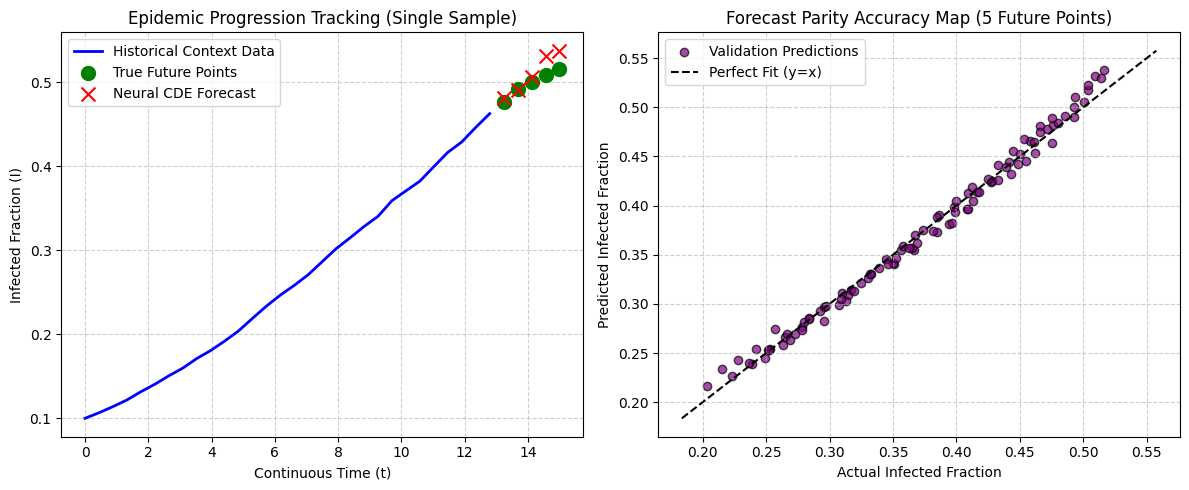

In [ ]:
# VISUALIZATION MODULE
num_plots=3
model.eval()
with torch.no_grad():
    # Generate neural predictions for validation cases
    predictions_tensor = model(val_coeffs)
    actuals_tensor = y_val

    val_loss = criterion(predictions_tensor, actuals_tensor)

    predictions = predictions_tensor.cpu().numpy()
    actuals = actuals_tensor.cpu().numpy()

print(np.shape(predictions))
plt.figure(figsize=(12, 5))

# Define parameters for times (consistent with training data generation)
total_timesteps = 35
context_timesteps = 30
forecast_timesteps = 5
all_times_generated = np.linspace(0, 15, total_timesteps)
historical_times_plot = all_times_generated[:context_timesteps]
future_times_plot = all_times_generated[context_timesteps:(context_timesteps + forecast_timesteps)]

# 1. Trajectory Timeline View (Sample #0)
plt.subplot(1, 2, 1)

# Plot historical trajectory feeding into the Neural CDE
time_hist = X_val_raw[0, :, 0].cpu().numpy()
inf_hist = X_val_raw[0, :, 2].cpu().numpy()
plt.plot(time_hist, inf_hist, label="Historical Context Data", color="blue", lw=2)

# Plot the true future points (5 points)
plt.scatter(future_times_plot, actuals[0], color="green", marker="o", s=100, label="True Future Points", zorder=5)
# Plot the predicted future points (5 points)
plt.scatter(future_times_plot, predictions[0], color="red", marker="x", s=100, label="Neural CDE Forecast", zorder=5)

plt.title("Epidemic Progression Tracking (Single Sample)")
plt.xlabel("Continuous Time (t)")
plt.ylabel("Infected Fraction (I)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# 2. Parity Scatter View (All Validation Samples)
plt.subplot(1, 2, 2)

# Flatten actuals and predictions for the parity plot
flat_actuals = actuals.flatten()
flat_predictions = predictions.flatten()

min_val = min(flat_actuals.min(), flat_predictions.min()) - 0.02
max_val = max(flat_actuals.max(), flat_predictions.max()) + 0.02

plt.scatter(flat_actuals, flat_predictions, color="purple", alpha=0.7, edgecolors='k', label="Validation Predictions")
plt.plot([min_val, max_val], [min_val, max_val], color="black", linestyle="--", label="Perfect Fit (y=x)")

plt.title("Forecast Parity Accuracy Map (5 Future Points)")
plt.xlabel("Actual Infected Fraction")
plt.ylabel("Predicted Infected Fraction")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

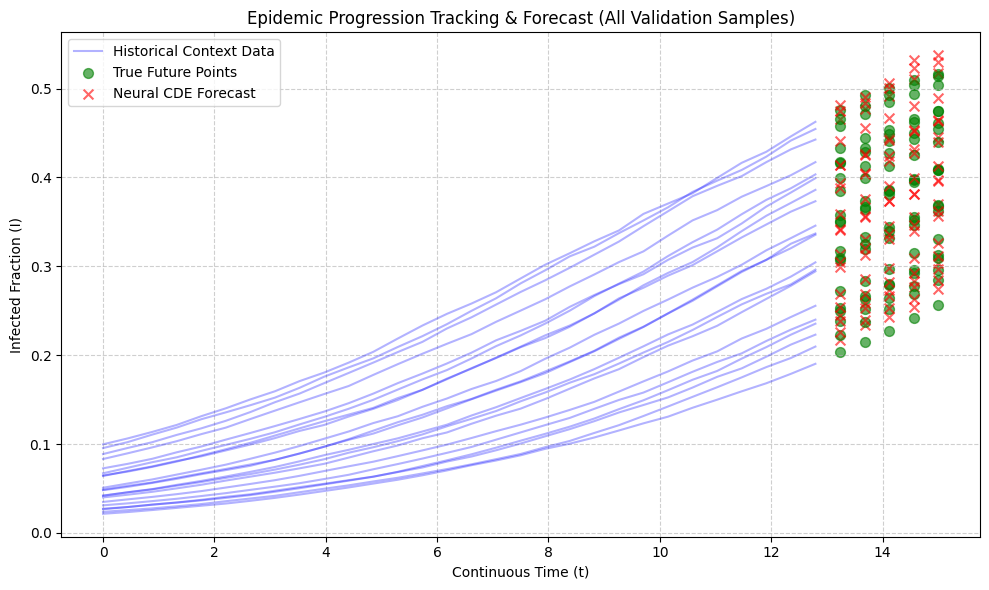

In [ ]:
# Plot all validation trajectories
plt.figure(figsize=(10, 6))

# Define parameters for times (consistent with training data generation)
total_timesteps = 35
context_timesteps = 30
forecast_timesteps = 5
all_times_generated = np.linspace(0, 15, total_timesteps)
historical_times_plot = all_times_generated[:context_timesteps]
future_times_plot = all_times_generated[context_timesteps:(context_timesteps + forecast_timesteps)]

for i in range(len(X_val_raw)):
    # Historical context data
    time_hist = X_val_raw[i, :, 0].cpu().numpy()
    inf_hist = X_val_raw[i, :, 2].cpu().numpy()
    plt.plot(time_hist, inf_hist, color='blue', alpha=0.3, label='_nolegend_' if i > 0 else 'Historical Context Data')

    # True future points (5 points)
    # y_val[i] has shape (5)
    plt.scatter(future_times_plot, y_val[i].cpu().numpy(), color='green', marker='o', s=50, alpha=0.6, label='_nolegend_' if i > 0 else 'True Future Points')

    # Neural CDE forecast (5 points)
    # predictions[i] has shape (5)
    plt.scatter(future_times_plot, predictions[i], color='red', marker='x', s=50, alpha=0.6, label='_nolegend_' if i > 0 else 'Neural CDE Forecast')

plt.title("Epidemic Progression Tracking & Forecast (All Validation Samples)")
plt.xlabel("Continuous Time (t)")
plt.ylabel("Infected Fraction (I)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# Install PySR (Julia dependencies are installed on first import in a fresh Colab runtime)
# If PySR is already installed, this cell can be skipped.
!pip install pysr

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.5/47.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.5/153.5 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.6/251.6 kB 18.2 MB/s eta 0:00:00


In [ ]:
# PY SR: DISCOVER THE UNKNOWN DYNAMICAL EQUATION
import numpy as np
import pandas as pd
from pysr import PySRRegressor

# ------------------------------------------------------------
# 1. Estimate the derivative from the observed trajectories
# ------------------------------------------------------------
# We use only observed data. No knowledge of beta, gamma, SIS,
# polynomial structure, or other mechanistic assumptions is used.

def make_symbolic_regression_data(data, response_index=1):

    if torch.is_tensor(data):
        data = data.detach().cpu().numpy()

    # Extract time points as a 1D array (assuming time points are the same across samples)
    t = data[0, :, 0]
    y_state = data[:, :, response_index]

    # Central finite-difference derivative. np.gradient handles
    # the interior points and one-sided differences at the ends.
    dy_dt = np.gradient(y_state, t, axis=1)

    # Every observed channel is allowed to participate in the equation.
    # Current notebook: channel 0 = time, channel 1 = infected fraction.
    X = data.reshape(-1, data.shape[-1])
    target = dy_dt.reshape(-1)

    mask = np.isfinite(X).all(axis=1) & np.isfinite(target)
    return X[mask], target[mask]

X_symbolic, dy_symbolic = make_symbolic_regression_data(
    X_train_raw,
    response_index=2
)

# Give physical names to the observed variables.
variable_names = ["t", "X_control", "I_val"]

print("Symbolic regression dataset:")
print("X shape:", X_symbolic.shape)
print("Target: dI/dt")
print("Variables searched:", variable_names)

# ------------------------------------------------------------
# 2. Symbolic regression -- functional form is NOT specified
# ------------------------------------------------------------
symbolic_model = PySRRegressor(
    # Increase these for a more extensive search in a real study.
    niterations=100,
    populations=8,
    population_size=50,
    maxsize=20,

    binary_operators=["+", "-", "*", "/"],
    parsimony=0.003,
    model_selection="best",

    # Useful for a noisy derivative estimate from simulated data.
    denoise=True,

    # Reproducibility.
    random_state=42,
    verbosity=1,
)

symbolic_model.fit(
    X_symbolic,
    dy_symbolic,
    variable_names=variable_names,
)

print("\nPySR equation candidates:")
display(symbolic_model.equations_[["complexity", "loss", "equation"]])

/usr/local/lib/python3.13/dist-packages/juliacall/__init__.py:61: UserWarning: torch was imported before juliacall. This may cause a segfault. To avoid this, import juliacall before importing torch. For updates, see https://github.com/pytorch/pytorch/issues/78829.
  warnings.warn(


[juliapkg] Found dependencies: /usr/local/lib/python3.13/dist-packages/pysr/juliapkg.json
[juliapkg] Found dependencies: /usr/local/lib/python3.13/dist-packages/juliacall/juliapkg.json
[juliapkg] Found dependencies: /usr/local/lib/python3.13/dist-packages/juliapkg/juliapkg.json
[juliapkg] Locating Julia 1.10.3 - 1.11
[juliapkg] WARNING: You have Julia 1.12.6 installed but 1.10.3 - 1.11 is required.
[juliapkg]   It is recommended that you upgrade Julia or install JuliaUp.
[juliapkg] Querying Julia versions from https://julialang-s3.julialang.org/bin/versions.json
[juliapkg] WARNING: About to install Julia 1.11.9 to /root/.julia/environments/pyjuliapkg/pyjuliapkg/install.
[juliapkg]   If you use juliapkg in more than one environment, you are likely to
[juliapkg]   have Julia installed in multiple locations. It is recommended to
[juliapkg]   install JuliaUp (https://github.com/JuliaLang/juliaup) or Julia
[juliapkg]   (https://julialang.org/downloads) yourself.
[juliapkg] Downloading Julia

/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__constant_value is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
Compiling Julia backend...
INFO:pysr.sr:Compiling Julia backend...
/usr/local/lib/pyt


PySR equation candidates:


,complexity,loss,equation
0,1,8.125728e-05,0.021348566
1,3,3.228861e-05,I_val * 0.112019375
2,5,1.212019e-05,(I_val * 0.07684174) + 0.008333631
3,7,8.146372e-09,((I_val * -0.28437805) - -0.19412711) * I_val
4,9,1.703384e-09,(((I_val * -0.28966272) + 0.19667546) * I_val)...
5,13,6.519604e-10,(I_val * 0.19117637) - ((I_val * I_val) * (0.2...
6,15,1.235138e-10,(I_val * 0.19315569) - ((I_val * (I_val * (0.2...
7,17,1.235129e-10,(I_val * 0.19315569) - ((I_val * ((I_val * 0.2...


In [ ]:
# SELECT AND DISPLAY THE DISCOVERED EQUATION
best_equation = symbolic_model.get_best()

print("Selected equation:")
print(best_equation)

# SymPy representation is useful for publication/reporting.
try:
    discovered_sympy = symbolic_model.sympy()
    print("\nSymPy form:")
    print(discovered_sympy)
except Exception as e:
    discovered_sympy = None
    print("\nSymPy conversion was unavailable:", e)

# Store the expression as text as well.
try:
    discovered_equation_text = str(best_equation["equation"])
except Exception:
    discovered_equation_text = str(best_equation)

print("\nHuman-readable discovered model:")
print("dI/dt =", discovered_equation_text)
print("\nActual dI/dt = I * (beta * S * I - gamma * I); average beta = 0.3, average gamma = 0.1")
print("with control: dI/dt actual = X_control * I * (beta * S * I - gamma * I); average beta = 0.3, average gamma = 0.1")

Selected equation:
complexity                                                      15
loss                                                           0.0
equation         (I_val * 0.19315569) - ((I_val * (I_val * (0.2...
score                                                     0.831816
sympy_format     I_val*0.19315569 - (I_val*I_val*(0.26897836 - ...
lambda_format    PySRFunction(X=>I_val*0.19315569 - (I_val*I_va...
Name: 6, dtype: object

SymPy form:
I_val*0.19315569 - (I_val*I_val*(0.26897836 - (-0.032612078)*I_val) + 0.00010161446)

Human-readable discovered model:
dI/dt = (I_val * 0.19315569) - ((I_val * (I_val * (0.26897836 - (I_val * -0.032612078)))) + 0.00010161446)

Actual dI/dt = I * (beta * S * I - gamma * I); average beta = 0.3, average gamma = 0.1
with control: dI/dt actual = X_control * I * (beta * S * I - gamma * I); average beta = 0.3, average gamma = 0.1


Model output without X_control

      Selected equation:
      complexity                                                       7
      loss                                                      0.000004
      equation               I_val * (0.19319922 - (I_val * 0.27951327))
      score                                                     0.713121
      sympy_format                 I_val*(0.19319922 - 0.27951327*I_val)
      lambda_format    PySRFunction(X=>I_val*(0.19319922 - 0.27951327...
      Name: 3, dtype: object

      SymPy form:
      I_val*(0.19319922 - 0.27951327*I_val)

      Human-readable discovered model:
      dI/dt = I_val * (0.19319922 - (I_val * 0.27951327))
      actual dI/dt = I * (beta * S * I - gamma * I); average beta = 0.3, average gamma = 0.1


Model output with X_control: fit is not good, does not include X_control at all; though some of the other models do (note: SymReg is indepeendent of NeuralODE which still gives a good fit)

      Selected equation:
      complexity                                                       7
      loss                                                      0.000006
      equation              (I_val + -0.6716516) * (I_val * -0.27112463)
      score                                                     0.422233
      sympy_format               (I_val - 0.6716516)*I_val*(-0.27112463)
      lambda_format    PySRFunction(X=>(I_val - 0.6716516)*I_val*(-0....
      Name: 3, dtype: object

      SymPy form:
      (I_val - 0.6716516)*I_val*(-0.27112463)

      Human-readable discovered model:
      dI/dt = (I_val + -0.6716516) * (I_val * -0.27112463)

      Actual dI/dt = I * (beta * S * I - gamma * I); average beta = 0.3, average gamma = 0.1
      with control: dI/dt actual = X_control * I * (beta * S * I - gamma * I); average beta = 0.3, average gamma = 0.1
